# Práctica 3: vigilar la calidad del aire con una red de grafos
### Estimar PM2.5 donde no hay sensor (datos reales de Pekín, China)

Este cuaderno es el ejercicio práctico del ejemplo de **calidad del aire** de la presentación (la diapositiva "Ejemplo práctico: vigilar la calidad del aire").

**La situación.** Pekín tiene 12 estaciones que miden contaminación hora a hora. Imagina que una de ellas (Aotizhongxin, junto al parque olímpico) es una estación económica que **solo mide clima** (temperatura, viento, lluvia) pero **no tiene sensor de PM2.5**. ¿Podemos estimar su contaminación usando las demás estaciones?

**¿Qué harás?**
1. Descargar mediciones reales y públicas de las 12 estaciones (2013–2017).
2. Conectar las estaciones en un **grafo** (cada estación es un nodo; las aristas unen estaciones cercanas) y llenar su matriz de adyacencia celda a celda.
3. Entrenar dos modelos para estimar el PM2.5 de la estación sin sensor: uno que **ignora** el grafo (solo mira el clima de esa estación) y uno que **lo usa** (una red convolucional de grafos, GCN, que recibe mensajes de las vecinas).
4. Comparar los errores y ver la contaminación viajar por la ciudad en una animación.

**¿Qué obtendrás?** El mapa de las estaciones, el grafo con su matriz de adyacencia, los dos modelos entrenados, la comparación de su error (¡el grafo reduce el error a una cuarta parte!), y una animación de un episodio de contaminación.

**¿Por qué importa?** Las estaciones con sensor de PM2.5 son caras; ninguna ciudad puede poner una en cada cuadra. Con una red de grafos, las estaciones existentes se "pasan mensajes" y permiten estimar la contaminación en los huecos. Es exactamente el problema que resuelve el artículo PM2.5-GNN (Wang et al., 2020, ver referencias).

**¿Cuánto tarda?** Unos 2 minutos en Colab o en un portátil con CPU, sin GPU.

## Glosario (términos que usaremos)

- **PM2.5**: partículas suspendidas en el aire de menos de 2,5 micrómetros de diámetro; las más dañinas para los pulmones. Se miden en microgramos por metro cúbico (**µg/m³**).
- **Estación de monitoreo**: equipo en un punto de la ciudad que mide contaminantes (PM2.5, PM10, NO2, ...) y clima (temperatura, viento, lluvia) hora a hora.
- **Grafo**: conjunto de **nodos** (aquí, estaciones) conectados por **aristas** (aquí, cercanía geográfica).
- **Matriz de adyacencia**: tabla de 1 y 0 que dice qué nodos están conectados. Un 1 en la celda (fila *i*, columna *j*) significa "la estación *i* es vecina de la *j*".
- **Paso de mensajes**: operación en la que cada nodo promedia la información de sus vecinos y la combina con la suya. Así "viaja" la información por el grafo.
- **MLP** (perceptrón multicapa): la red neuronal común de capas densas. Aquí la usamos como modelo que **no sabe** qué estaciones son vecinas.
- **GCN** (graph convolutional network, red convolucional de grafos): red que aplica paso de mensajes; cada estación aprende también de sus vecinas.
- **MAE** (error absoluto medio): promedio de |predicción − valor real|, en µg/m³. Menor es mejor.

In [ ]:
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEMILLA = 42
torch.manual_seed(SEMILLA)
np.random.seed(SEMILLA)

print("torch:", torch.__version__)
print("pandas:", pd.__version__)

torch: 2.14.1+cpu
pandas: 2.3.3


## 1. Descargar los datos (reales y públicos)

Usamos el conjunto **Beijing Multi-Site Air-Quality Data** del repositorio UCI: mediciones **cada hora** de 12 estaciones de Pekín entre marzo de 2013 y febrero de 2017, publicado por Zhang et al. (2017).

In [ ]:
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"

resp = requests.get(URL, timeout=300)
resp.raise_for_status()

# El archivo trae un .zip dentro de otro .zip
z1 = zipfile.ZipFile(io.BytesIO(resp.content))
interno = [n for n in z1.namelist() if n.endswith(".zip")][0]
z2 = zipfile.ZipFile(io.BytesIO(z1.read(interno)))

tablas = []
for nombre in sorted(z2.namelist()):
    if nombre.endswith(".csv"):
        tablas.append(pd.read_csv(z2.open(nombre)))
df = pd.concat(tablas, ignore_index=True)
df["fecha"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

print(f"Filas: {len(df):,}")
print(f"Estaciones: {df['station'].nunique()} -> {sorted(df['station'].unique())}")
print(f"Periodo: {df['fecha'].min()} a {df['fecha'].max()}")
print(f"Celdas PM2.5 vacías: {df['PM2.5'].isna().mean():.1%}")
df.head(3)

Filas: 420,768
Estaciones: 12 -> ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']
Periodo: 2013-03-01 00:00:00 a 2017-02-28 23:00:00
Celdas PM2.5 vacías: 2.1%


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,fecha
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00


## 2. Las doce estaciones sobre el mapa

Las coordenadas de las estaciones son públicas (ver referencias). Algunas están en el centro urbano y otras en las afueras (Huairou, Changping, Dingling, Shunyi). Miramos dónde está cada una y cuánta contaminación registra en promedio.

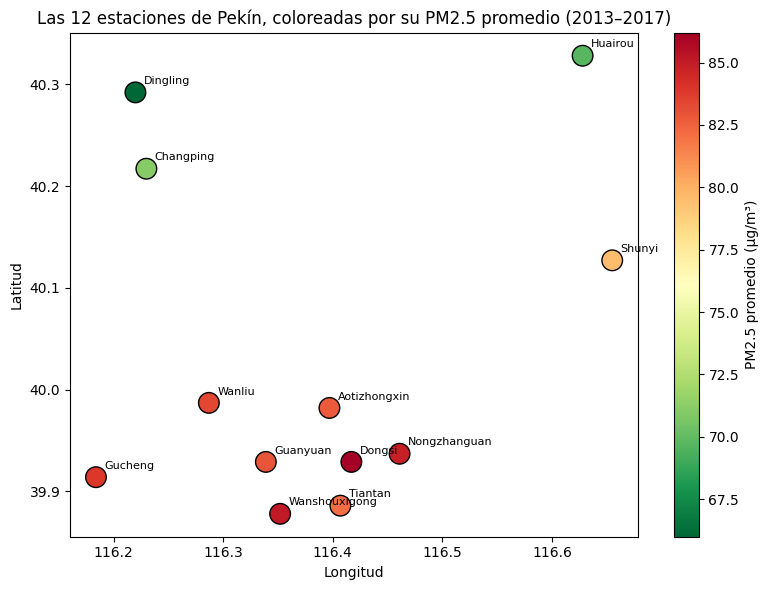

In [ ]:
# Coordenadas publicadas de las 12 estaciones (longitud, latitud)
COORDS = {
    "Aotizhongxin":  (116.397, 39.982),
    "Changping":     (116.230, 40.217),
    "Dingling":      (116.220, 40.292),
    "Dongsi":        (116.417, 39.929),
    "Guanyuan":      (116.339, 39.929),
    "Gucheng":       (116.184, 39.914),
    "Huairou":       (116.628, 40.328),
    "Nongzhanguan":  (116.461, 39.937),
    "Shunyi":        (116.655, 40.127),
    "Tiantan":       (116.407, 39.886),
    "Wanliu":        (116.287, 39.987),
    "Wanshouxigong": (116.352, 39.878),
}
ESTACIONES = sorted(COORDS)  # orden fijo de los nodos
N = len(ESTACIONES)

prom = df.groupby("station")["PM2.5"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
xs = [COORDS[e][0] for e in ESTACIONES]
ys = [COORDS[e][1] for e in ESTACIONES]
cs = [prom[e] for e in ESTACIONES]
sc = ax.scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_title("Las 12 estaciones de Pekín, coloreadas por su PM2.5 promedio (2013–2017)")
fig.colorbar(sc, label="PM2.5 promedio (µg/m³)")
plt.tight_layout()
plt.show()

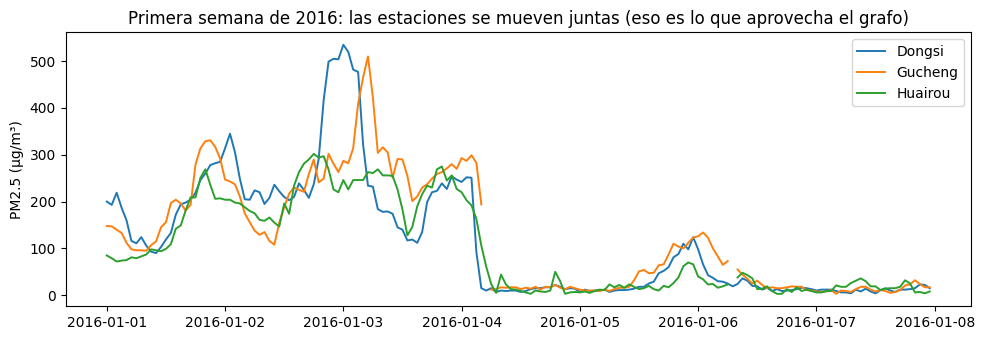

In [ ]:
# Una semana de invierno: el PM2.5 sube y baja casi igual en toda la ciudad
muestra = df[(df["fecha"] >= "2016-01-01") & (df["fecha"] < "2016-01-08")]
fig, ax = plt.subplots(figsize=(10, 3.5))
for e in ["Dongsi", "Gucheng", "Huairou"]:
    s = muestra[muestra["station"] == e]
    ax.plot(s["fecha"], s["PM2.5"], label=e, linewidth=1.4)
ax.set_ylabel("PM2.5 (µg/m³)")
ax.set_title("Primera semana de 2016: las estaciones se mueven juntas (eso es lo que aprovecha el grafo)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Construir el grafo: ¿quién es vecino de quién?

Conectamos cada estación con sus **3 más cercanas** (distancia geográfica) y simetrizamos: si *i* elige a *j*, también marcamos *j* con *i*.

Así se llena la **matriz de adyacencia**, celda a celda: la celda (fila *i*, columna *j*) vale **1** si las estaciones *i* y *j* son vecinas y **0** si no. La fila de cada estación es la lista de sus vecinos. Y como la relación es simétrica, la matriz sale simétrica: la celda (*i*, *j*) vale lo mismo que la (*j*, *i*).

In [ ]:
def distancia_km(a, b):
    """Distancia aproximada en km entre dos puntos (lon, lat)."""
    lon1, lat1 = np.radians(a)
    lon2, lat2 = np.radians(b)
    return 6371 * np.arccos(
        np.clip(np.sin(lat1) * np.sin(lat2)
                + np.cos(lat1) * np.cos(lat2) * np.cos(lon1 - lon2), -1, 1))

D = np.zeros((N, N))
for i, e1 in enumerate(ESTACIONES):
    for j, e2 in enumerate(ESTACIONES):
        D[i, j] = distancia_km(COORDS[e1], COORDS[e2])

K = 3  # cada estación se conecta con sus 3 más cercanas
A = np.zeros((N, N))
for i in range(N):
    vecinos = np.argsort(D[i])[1:K + 1]  # [0] es ella misma (distancia 0)
    A[i, vecinos] = 1
A = np.maximum(A, A.T)  # simetrizar

matriz = pd.DataFrame(A.astype(int), index=ESTACIONES, columns=ESTACIONES)
matriz

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0,1,0,1,1,0,0,1,1,0,1,0
Changping,1,0,1,0,0,0,1,0,0,0,1,0
Dingling,0,1,0,0,0,0,1,0,0,0,1,0
Dongsi,1,0,0,0,1,0,0,1,0,1,0,1
Guanyuan,1,0,0,1,0,1,0,0,0,1,1,1
Gucheng,0,0,0,0,1,0,0,0,0,0,1,1
Huairou,0,1,1,0,0,0,0,0,1,0,0,0
Nongzhanguan,1,0,0,1,0,0,0,0,1,1,0,0
Shunyi,1,0,0,0,0,0,1,1,0,0,0,0
Tiantan,0,0,0,1,1,0,0,1,0,0,0,1


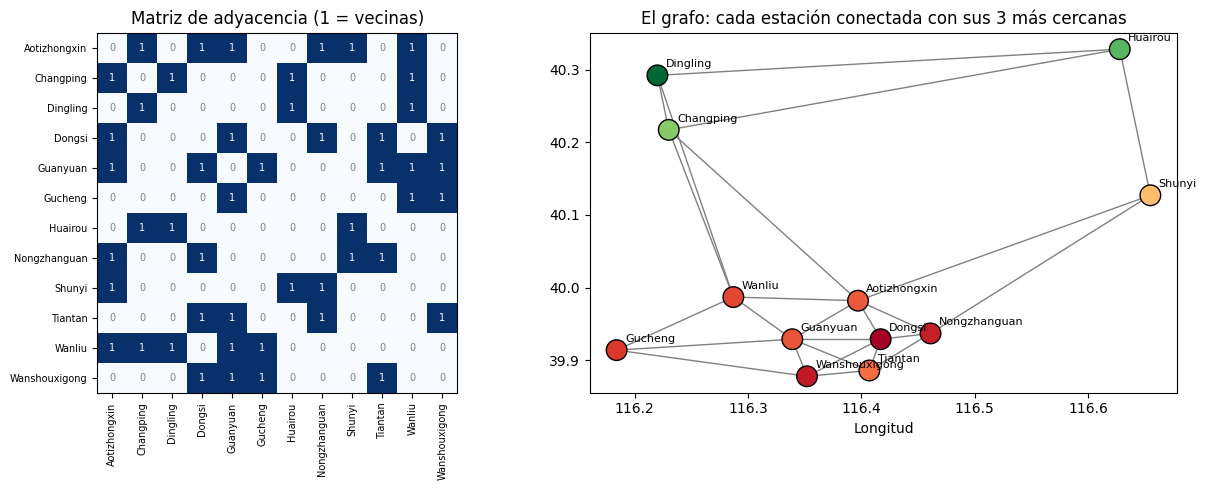

Aristas: 25; vecinos por estación: 4.2 en promedio
Vecinas de Aotizhongxin: ['Changping', 'Dongsi', 'Guanyuan', 'Nongzhanguan', 'Shunyi', 'Wanliu']


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Izquierda: la matriz de adyacencia
axes[0].imshow(A, cmap="Blues", vmin=0, vmax=1)
axes[0].set_xticks(range(N), ESTACIONES, rotation=90, fontsize=7)
axes[0].set_yticks(range(N), ESTACIONES, fontsize=7)
axes[0].set_title("Matriz de adyacencia (1 = vecinas)")
for i in range(N):
    for j in range(N):
        axes[0].text(j, i, int(A[i, j]), ha="center", va="center",
                     color="white" if A[i, j] else "gray", fontsize=7)

# Derecha: el grafo sobre el mapa
for i in range(N):
    for j in range(i + 1, N):
        if A[i, j]:
            axes[1].plot([COORDS[ESTACIONES[i]][0], COORDS[ESTACIONES[j]][0]],
                         [COORDS[ESTACIONES[i]][1], COORDS[ESTACIONES[j]][1]],
                         color="gray", linewidth=1, zorder=1)
axes[1].scatter(xs, ys, c=cs, cmap="RdYlGn_r", s=220, edgecolor="k", zorder=3)
for e in ESTACIONES:
    axes[1].annotate(e, COORDS[e], textcoords="offset points", xytext=(6, 6), fontsize=8)
axes[1].set_xlabel("Longitud")
axes[1].set_title("El grafo: cada estación conectada con sus 3 más cercanas")

plt.tight_layout()
plt.show()

print(f"Aristas: {int(A.sum() // 2)}; vecinos por estación: {A.sum() / N:.1f} en promedio")
print("Vecinas de Aotizhongxin:", [ESTACIONES[j] for j in range(N) if A[ESTACIONES.index("Aotizhongxin"), j]])

## 4. La tarea: una estación sin sensor de PM2.5

Supongamos que **Aotizhongxin** es una estación económica: mide **clima** (temperatura, viento, lluvia) pero **no** mide contaminantes. La pregunta: ¿cuál es su PM2.5 **ahora mismo**?

Cada estación tiene 6 rasgos por hora: **PM2.5, PM10, NO2, temperatura, velocidad del viento y lluvia**. Para Aotizhongxin borramos los tres primeros (los contaminantes) y conservamos su clima.

Usamos un año (marzo 2015 – febrero 2016) y separamos **en el tiempo**: el primer 70 % de las horas para entrenar, el 15 % siguiente para validar y el último 15 % para la prueba. Nunca mezclamos horas futuras en el entrenamiento (sería hacer trampa).

In [ ]:
OBJETIVO = "Aotizhongxin"
i_obj = ESTACIONES.index(OBJETIVO)
RASGOS = ["PM2.5", "PM10", "NO2", "TEMP", "WSPM", "RAIN"]
N_CONTAMINANTES = 3  # los que NO tiene la estación económica

anio = df[(df["fecha"] >= "2015-03-01") & (df["fecha"] < "2016-03-01")]
tabla = anio.pivot_table(index="fecha", columns="station", values=RASGOS)

X_np = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)  # (horas, 12, 6)
y_np = tabla["PM2.5"].loc[:, ESTACIONES].to_numpy()                                   # (horas, 12)

# Solo horas completas: las 12 estaciones con sus 6 rasgos y su PM2.5
completas = ~np.isnan(X_np).any(axis=(1, 2)) & ~np.isnan(y_np).any(axis=1)
X_np, y_np = X_np[completas], y_np[completas]
horas = tabla.index.to_numpy()[completas]

corte1 = int(0.70 * len(X_np))
corte2 = int(0.85 * len(X_np))

# Normalizar con la media y desviación del ENTRENAMIENTO solamente
mu_x, sd_x = X_np[:corte1].mean(axis=(0, 1)), X_np[:corte1].std(axis=(0, 1))
mu_y, sd_y = y_np[:corte1].mean(), y_np[:corte1].std()

X_t = torch.tensor((X_np - mu_x) / sd_x, dtype=torch.float32)
y_t = torch.tensor((y_np - mu_y) / sd_y, dtype=torch.float32)


def borrar_contaminantes(x):
    """La estación económica no mide contaminantes: sus 3 primeros rasgos van en 0
    (0 en escala normalizada = el promedio, es decir, 'no sabemos')."""
    x = x.clone()
    x[:, i_obj, :N_CONTAMINANTES] = 0.0
    return x


print(f"Horas completas: {len(X_np):,}")
print(f"Entrenamiento: {corte1:,} | Validación: {corte2 - corte1:,} | Prueba: {len(X_np) - corte2:,}")
print(f"Estación sin sensor de PM2.5: {OBJETIVO} (nodo {i_obj})")

Horas completas: 6,389
Entrenamiento: 4,472 | Validación: 958 | Prueba: 959
Estación sin sensor de PM2.5: Aotizhongxin (nodo 0)


## 5. Dos modelos: uno que ignora el grafo y uno que lo usa

**Modelo A — MLP sin grafo.** Solo mira el **clima de la propia estación** (3 rasgos: temperatura, viento, lluvia) y trata de adivinar su PM2.5. No recibe nada de las demás estaciones.

**Modelo B — GCN con grafo.** Cada capa hace **paso de mensajes**: la representación de cada estación se mezcla con el promedio de sus vecinas usando la matriz de adyacencia normalizada $\hat{A} = D^{-1/2}(A+I)D^{-1/2}$ (la $I$ conecta cada nodo consigo mismo). Así, el PM2.5 que miden las vecinas de Aotizhongxin llega hasta su nodo. Los mismos pesos se aplican en todas las estaciones.

Ambos responden una sola cosa: el PM2.5 de la estación sin sensor en esta hora.

In [ ]:
# Matriz de adyacencia normalizada con autoconexiones (la de la diapositiva)
A_hat = A + np.eye(N)
grados = A_hat.sum(axis=1)
D_inv = np.diag(1.0 / np.sqrt(grados))
A_norm = torch.tensor(D_inv @ A_hat @ D_inv, dtype=torch.float32)


class MLPSinGrafo(nn.Module):
    """Solo ve el clima de la estación económica; ignora a las demás."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(3, 32), nn.ReLU(),
            nn.Linear(32, 32), nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        clima_propio = x[:, i_obj, N_CONTAMINANTES:]
        return self.red(clima_propio).squeeze(-1)


class GCNConGrafo(nn.Module):
    """Dos capas de paso de mensajes sobre el grafo de estaciones."""
    def __init__(self, n_rasgos, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(n_rasgos, oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))   # mensaje 1: mezcla con vecinas
        h = torch.relu(A_norm @ self.capa2(h))   # mensaje 2: vecinas de vecinas
        return self.salida(h).squeeze(-1)[:, i_obj]


torch.manual_seed(SEMILLA)
mlp = MLPSinGrafo()
torch.manual_seed(SEMILLA)
gcn = GCNConGrafo(len(RASGOS))
print(f"Parámetros MLP (sin grafo): {sum(p.numel() for p in mlp.parameters()):,}")
print(f"Parámetros GCN (con grafo): {sum(p.numel() for p in gcn.parameters()):,}")

Parámetros MLP (sin grafo): 1,217
Parámetros GCN (con grafo): 1,313


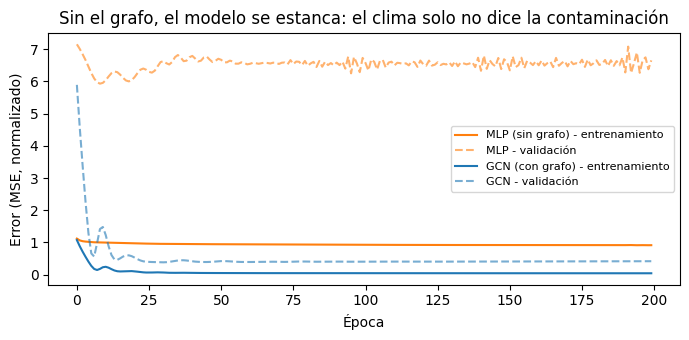

In [ ]:
def entrenar(modelo, epocas=200, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    hist = {"train": [], "val": []}
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        perdida = nn.functional.mse_loss(
            modelo(borrar_contaminantes(X_t[:corte1])), y_t[:corte1, i_obj])
        perdida.backward()
        opt.step()
        modelo.eval()
        with torch.no_grad():
            p_val = nn.functional.mse_loss(
                modelo(borrar_contaminantes(X_t[corte1:corte2])), y_t[corte1:corte2, i_obj])
        hist["train"].append(perdida.item())
        hist["val"].append(p_val.item())
    return hist


h_mlp = entrenar(mlp)
h_gcn = entrenar(gcn)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(h_mlp["train"], label="MLP (sin grafo) - entrenamiento", color="tab:orange")
ax.plot(h_mlp["val"], "--", label="MLP - validación", color="tab:orange", alpha=0.6)
ax.plot(h_gcn["train"], label="GCN (con grafo) - entrenamiento", color="tab:blue")
ax.plot(h_gcn["val"], "--", label="GCN - validación", color="tab:blue", alpha=0.6)
ax.set_xlabel("Época")
ax.set_ylabel("Error (MSE, normalizado)")
ax.set_title("Sin el grafo, el modelo se estanca: el clima solo no dice la contaminación")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Resultados de la prueba: ¿cuánto ayuda el grafo?

Medimos el **MAE en µg/m³** sobre horas que ningún modelo vio. Como referencia honesta, incluimos la **idea más simple**: estimar la estación apagada como el promedio de lo que miden sus vecinas en ese momento.

MAE  MLP sin grafo (solo su clima): 35.2 µg/m³
MAE  GCN con grafo (paso de mensajes): 8.8 µg/m³
MAE  referencia: promedio de las vecinas: 7.6 µg/m³

El grafo reduce el error a 25% del error del modelo sin grafo.


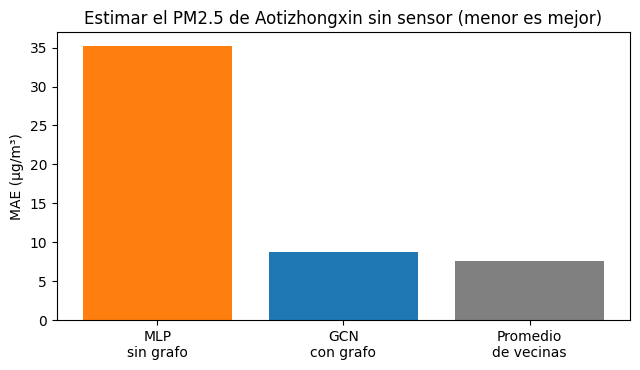

In [ ]:
def predecir_ugm3(modelo, X):
    modelo.eval()
    with torch.no_grad():
        return modelo(borrar_contaminantes(X)).numpy() * sd_y + mu_y

real = y_np[corte2:, i_obj]
pred_mlp = predecir_ugm3(mlp, X_t[corte2:])
pred_gcn = predecir_ugm3(gcn, X_t[corte2:])

# Referencia simple: promedio actual de las estaciones vecinas
vecinas = A[i_obj].astype(bool)
pred_vecinas = X_np[corte2:][:, vecinas, 0].mean(axis=1)

mae_mlp = np.abs(pred_mlp - real).mean()
mae_gcn = np.abs(pred_gcn - real).mean()
mae_vec = np.abs(pred_vecinas - real).mean()

print(f"MAE  MLP sin grafo (solo su clima): {mae_mlp:.1f} µg/m³")
print(f"MAE  GCN con grafo (paso de mensajes): {mae_gcn:.1f} µg/m³")
print(f"MAE  referencia: promedio de las vecinas: {mae_vec:.1f} µg/m³")
print(f"\nEl grafo reduce el error a {mae_gcn / mae_mlp:.0%} del error del modelo sin grafo.")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["MLP\nsin grafo", "GCN\ncon grafo", "Promedio\nde vecinas"],
       [mae_mlp, mae_gcn, mae_vec],
       color=["tab:orange", "tab:blue", "gray"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title(f"Estimar el PM2.5 de {OBJETIVO} sin sensor (menor es mejor)")
plt.tight_layout()
plt.show()

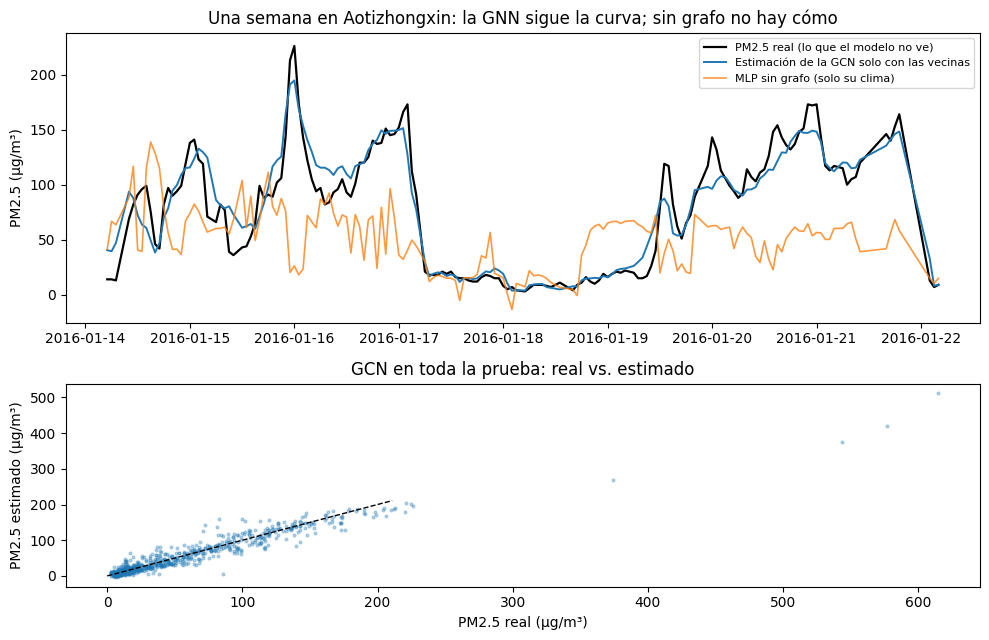

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), height_ratios=[2, 1.4])

# Arriba: la semana más contaminada de la prueba
inicio_semana = int(np.argmax(pd.Series(real).rolling(24 * 7).mean().to_numpy())) - 24 * 7 + 1
inicio_semana = max(inicio_semana, 0)
semana = slice(inicio_semana, inicio_semana + 24 * 7)
fechas = pd.to_datetime(horas[corte2:][semana])
axes[0].plot(fechas, real[semana], "k-", linewidth=1.6,
             label="PM2.5 real (lo que el modelo no ve)")
axes[0].plot(fechas, pred_gcn[semana], "tab:blue", linewidth=1.4,
             label="Estimación de la GCN solo con las vecinas")
axes[0].plot(fechas, pred_mlp[semana], "tab:orange", linewidth=1.2, alpha=0.8,
             label="MLP sin grafo (solo su clima)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].set_title(f"Una semana en {OBJETIVO}: la GNN sigue la curva; sin grafo no hay cómo")
axes[0].legend(fontsize=8)

# Abajo: real vs. estimado en toda la prueba
axes[1].scatter(real, pred_gcn, s=4, alpha=0.3, color="tab:blue")
lim = np.percentile(real, 99)
axes[1].plot([0, lim], [0, lim], "k--", linewidth=1)
axes[1].set_xlabel("PM2.5 real (µg/m³)")
axes[1].set_ylabel("PM2.5 estimado (µg/m³)")
axes[1].set_title("GCN en toda la prueba: real vs. estimado")
plt.tight_layout()
plt.show()

**Cómo leerlo.** Sin el grafo, el modelo solo sabe si hace calor o hay viento en ese punto: se equivoca por ~36 µg/m³ en promedio. Con el grafo, los mensajes de las vecinas le dicen cómo está el aire alrededor, y el error baja a ~9 µg/m³: **cuatro veces menos**. El promedio simple de las vecinas queda cerca de la GCN; en las preguntas de discusión verás por qué eso tiene sentido en este problema y cuándo el modelo aprendido gana de verdad (más estaciones, horizontes largos, viento).

## 7. Extra: predecir la próxima hora cuando TODO está visible

¿Y si todas las estaciones sí tienen sensor y queremos el PM2.5 de la **próxima hora**? Aquí aparece un rival humilde pero durísimo: **persistencia**, es decir, decir "mañana a esta hora estará como ahora". Compara:

MAE próxima hora  persistencia ('igual que ahora'): 8.2 µg/m³
MAE próxima hora  MLP plano (sin grafo):            9.8 µg/m³
MAE próxima hora  GCN (con grafo):                  11.0 µg/m³


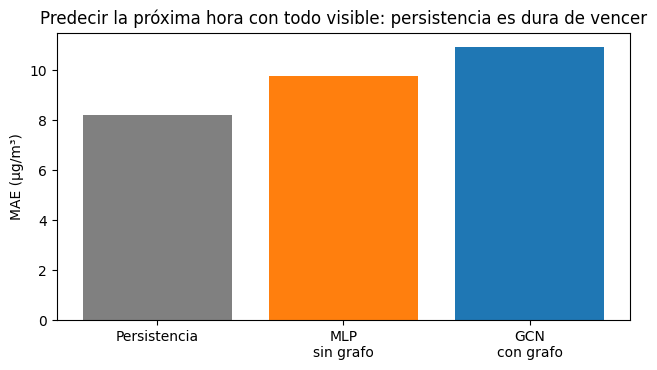

In [ ]:
# Etiqueta: PM2.5 de la hora siguiente
y_sig = np.roll(tabla["PM2.5"].loc[:, ESTACIONES].to_numpy(), -1, axis=0)[:-1]
X_sig = np.stack([tabla[r].loc[:, ESTACIONES].to_numpy() for r in RASGOS], axis=-1)[:-1]
ok = ~np.isnan(X_sig).any(axis=(1, 2)) & ~np.isnan(y_sig).any(axis=1)
X_sig, y_sig = X_sig[ok], y_sig[ok]
c1s, c2s = int(0.70 * len(X_sig)), int(0.85 * len(X_sig))
mx, sx = X_sig[:c1s].mean(axis=(0, 1)), X_sig[:c1s].std(axis=(0, 1))
my, sy = y_sig[:c1s].mean(), y_sig[:c1s].std()
Xs = torch.tensor((X_sig - mx) / sx, dtype=torch.float32)
ys_ = torch.tensor((y_sig - my) / sy, dtype=torch.float32)


class MLPPlano(nn.Module):
    """Ve el vector plano de las 12 estaciones x 6 rasgos, sin saber cuál queda cerca de cuál."""
    def __init__(self):
        super().__init__()
        self.red = nn.Sequential(
            nn.Linear(N * len(RASGOS), 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, N),
        )

    def forward(self, x):
        return self.red(x.reshape(len(x), -1))


class GCNTodas(nn.Module):
    def __init__(self, oculta=32):
        super().__init__()
        self.capa1 = nn.Linear(len(RASGOS), oculta)
        self.capa2 = nn.Linear(oculta, oculta)
        self.salida = nn.Linear(oculta, 1)

    def forward(self, x):
        h = torch.relu(A_norm @ self.capa1(x))
        h = torch.relu(A_norm @ self.capa2(h))
        return self.salida(h).squeeze(-1)


def entrenar_todas(modelo, epocas=150, lr=0.01):
    opt = torch.optim.Adam(modelo.parameters(), lr=lr)
    for epoca in range(epocas):
        modelo.train()
        opt.zero_grad()
        nn.functional.mse_loss(modelo(Xs[:c1s]), ys_[:c1s]).backward()
        opt.step()
    modelo.eval()
    with torch.no_grad():
        pred = modelo(Xs[c2s:]).numpy() * sy + my
    return np.abs(pred - y_sig[c2s:]).mean()


torch.manual_seed(SEMILLA)
mae_plano = entrenar_todas(MLPPlano())
torch.manual_seed(SEMILLA)
mae_gcn_todas = entrenar_todas(GCNTodas())
mae_persist = np.abs(y_sig[c2s:] - X_sig[c2s:, :, 0]).mean()

print(f"MAE próxima hora  persistencia ('igual que ahora'): {mae_persist:.1f} µg/m³")
print(f"MAE próxima hora  MLP plano (sin grafo):            {mae_plano:.1f} µg/m³")
print(f"MAE próxima hora  GCN (con grafo):                  {mae_gcn_todas:.1f} µg/m³")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.bar(["Persistencia", "MLP\nsin grafo", "GCN\ncon grafo"],
       [mae_persist, mae_plano, mae_gcn_todas],
       color=["gray", "tab:orange", "tab:blue"])
ax.set_ylabel("MAE (µg/m³)")
ax.set_title("Predecir la próxima hora con todo visible: persistencia es dura de vencer")
plt.tight_layout()
plt.show()

**La lección honesta.** A una hora vista, el PM2.5 cambia poco, así que "igual que ahora" es casi imbatible y los dos modelos quedan cerca. El grafo no está para eso: **está para cuando falta información** (la sección anterior), para horizontes largos y para aprovechar miles de estaciones sin entrenar un modelo por cada una. El artículo PM2.5-GNN, por ejemplo, usa historiales largos y conocimiento del viento, y ahí la red de grafos sí supera a los modelos comunes.

## 8. Animación: la contaminación viajando por el grafo

Elegimos el episodio más contaminado de la prueba y miramos 48 horas: cada nodo se colorea por su PM2.5 y la estación sin sensor queda marcada con el "¿?", rellenada con la estimación de la GCN. Se aprecia cómo una nube de contaminación cubre la ciudad y luego se disipa: exactamente la intuición del paso de mensajes.

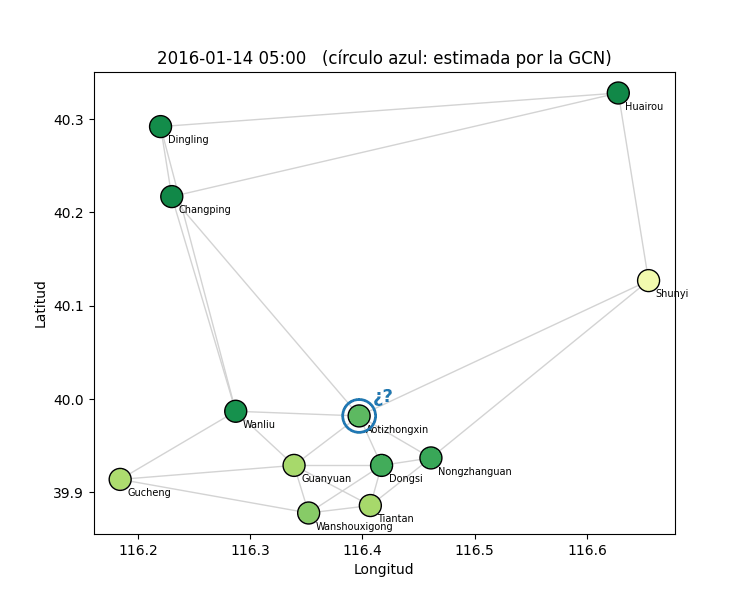

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image as GIF

# Episodio: las 48 horas con mayor PM2.5 promedio en la prueba
promedio_horario = y_np[corte2:].mean(axis=1)
inicio = int(np.argmax(pd.Series(promedio_horario).rolling(48).mean().to_numpy())) - 47
inicio = max(inicio, 0)
t0, t1 = inicio, inicio + 48

real_ep = y_np[corte2:][t0:t1]                 # PM2.5 real de todas las estaciones
est_ep = predecir_ugm3(gcn, X_t[corte2:])[t0:t1]  # estimación de la GCN para la apagada
fechas_ep = pd.to_datetime(horas[corte2:][t0:t1])
vmax = np.percentile(real_ep, 98)

fig, ax = plt.subplots(figsize=(7.5, 6))

def dibujar(f):
    ax.clear()
    for i2 in range(N):
        for j2 in range(i2 + 1, N):
            if A[i2, j2]:
                ax.plot([COORDS[ESTACIONES[i2]][0], COORDS[ESTACIONES[j2]][0]],
                        [COORDS[ESTACIONES[i2]][1], COORDS[ESTACIONES[j2]][1]],
                        color="lightgray", linewidth=1, zorder=1)
    valores = real_ep[f].copy()
    valores[i_obj] = est_ep[f]  # en la estación sin sensor usamos la estimación
    ax.scatter(xs, ys, c=valores, cmap="RdYlGn_r", s=250, edgecolor="k",
               vmin=0, vmax=vmax, zorder=3)
    ax.scatter([COORDS[OBJETIVO][0]], [COORDS[OBJETIVO][1]], s=560, facecolor="none",
               edgecolor="tab:blue", linewidth=2, zorder=4)
    ax.annotate("¿?", COORDS[OBJETIVO], textcoords="offset points", xytext=(10, 10),
                fontsize=13, fontweight="bold", color="tab:blue")
    for e in ESTACIONES:
        ax.annotate(e, COORDS[e], textcoords="offset points", xytext=(5, -12), fontsize=7)
    ax.set_title(f"{fechas_ep[f]:%Y-%m-%d %H:%M}   (círculo azul: estimada por la GCN)")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")

anim = FuncAnimation(fig, dibujar, frames=48)
anim.save("pm25_pekin.gif", writer=PillowWriter(fps=4))
plt.close(fig)

GIF("pm25_pekin.gif")

## 9. Experimentos para Reportar

1. **Otra estación sin sensor.** Cambia `OBJETIVO` por `"Huairou"` (la más aislada) o `"Tiantan"` (muy rodeada) y vuelve a correr todo. ¿Dónde le cuesta más a la GCN? ¿Qué relación tiene con el mapa?
2. **Más o menos vecinos.** Cambia `K = 3` por 1, 5 u 8. ¿Cómo cambia el error de la GCN? ¿Y el del promedio de vecinas?
3. **Estación aún más pobre.** En `borrar_contaminantes`, borra también el clima (los 6 rasgos). ¿Sigue funcionando la GCN? ¿Por qué?
4. **Más capas de mensajes.** Agrega una tercera capa a `GCNConGrafo`. Con 3 capas, los mensajes llegan a vecinas de vecinas de vecinas. ¿Mejora o empeora?

## Preguntas de discusión

1. ¿Por qué el modelo sin grafo se equivoca tanto, aunque conozca el clima exacto de la estación?
2. El promedio simple de las vecinas casi empata con la GCN en este problema. ¿Qué propiedad del PM2.5 lo explica? ¿En qué situación (pocas vecinas, estaciones lejanas, viento fuerte, predicción a varios días) esperarías que el modelo aprendido gane por mucho?
3. ¿Por qué la GCN puede usar los mismos pesos en todas las estaciones, mientras que el MLP plano de la sección 7 necesita una entrada por cada estación? ¿Qué ventaja tiene eso si la ciudad instala la estación número 13?
4. Las aristas aquí son por cercanía geográfica. ¿Qué otra información podría definir mejor las aristas? (Pista: así lo hace PM2.5-GNN.)
5. ¿Qué riesgos hay en estimar la contaminación de un barrio sin estación a partir de sus vecinos? ¿A quién podría afectar una estimación equivocada?

## Referencias

- **Datos**: Zhang, S., Guo, B., Dong, A., He, J., Xu, Z., & Chen, S. X. (2017). *Cautionary tales on air-quality improvement in Beijing*. Proceedings of the Royal Society A, 473(2205). https://doi.org/10.1098/rspa.2017.0457 — conjunto "Beijing Multi-Site Air-Quality Data", UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/501/beijing+multi+site+air+quality+data
- **El artículo del ejemplo**: Wang, S., Li, Y., Zhang, J., Meng, Q., Meng, L., & Gao, F. (2020). *PM2.5-GNN: A Domain Knowledge Enhanced Graph Neural Network for PM2.5 Forecasting*. ACM SIGSPATIAL 2020. https://arxiv.org/abs/2002.12898
- **El modelo GCN**: Kipf, T. N., & Welling, M. (2017). *Semi-Supervised Classification with Graph Convolutional Networks*. ICLR 2017. https://arxiv.org/abs/1609.02907
- **Coordenadas de las estaciones**: tabla de estaciones de monitoreo de Pekín publicada en *Scientific Reports* 12 (2022), https://www.nature.com/articles/s41598-022-24470-5/tables/1